### DAHITI and Hydroweb validation
Read data → match lakes → match dates → merge and save.



In [29]:
from pathlib import Path
import geopandas as gpd
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

#### Configuration

Run from the project root, or set `project_root` to its absolute path.


In [18]:
path_lakes = 'data/lake/hydrolake_hma/HydroLakes_v10_hma.gpkg' 
path_insitu_nc = 'data/validation/lake_height/lake_station_lakes_all.nc' 
dir_hydroweb = 'data/water_height/hydroweb/hma_lakes' 
dir_dahiti = 'data/water_height/dahiti' 
path_save_gpkg = 'data/water_height/merged_data.gpkg' 
tolerance_days = 3


#### 1. Read data.  
Normalize dates to midnight and discard invalid dates or water levels.


In [19]:
def water_level_table(frame):
    """Standardize a table with date, water_level, and WGS84 geometry."""
    frame = frame.copy()
    frame['date'] = pd.to_datetime(frame['date'], errors='coerce').dt.normalize()
    frame['water_level'] = pd.to_numeric(frame['water_level'], errors='coerce')
    frame = frame.dropna(subset=['date', 'water_level', 'geometry'])
    return gpd.GeoDataFrame(frame[['date', 'water_level', 'geometry']], crs=4326)


def read_insitu(path_insitu_nc):
    """Read water levels and station coordinates from NetCDF."""
    with xr.open_dataset(path_insitu_nc) as ds:
        obs_df = pd.DataFrame({
            'station_index': ds['station_index'].values,
            'date': ds['time'].values,
            'water_level': ds['water_level'].values
        })
        
        station_df = pd.DataFrame({
            'station_index': ds['station_id'].values,
            'lon': ds['lon'].values,
            'lat': ds['lat'].values
        })
        
    frame = obs_df.merge(station_df, on='station_index', validate='many_to_one')
    frame['geometry'] = gpd.points_from_xy(frame['lon'], frame['lat'])
    # Match the datetime precision used by Hydroweb and DAHITI.
    frame['date'] = frame['date'].astype('datetime64[us]')
    return water_level_table(frame)


def read_hydroweb(dir_hydroweb):
    """Read all Hydroweb TXT files into one water-level table."""
    tables = []
    for path in sorted(Path(dir_hydroweb).glob('*.txt')):
        lines = path.read_text().splitlines()
        metadata = dict(item.split('=', 1) for item in lines[0].split(';') if '=' in item)
        rows = [line.split(';') for line in lines[1:]
                if not line.startswith('#') and ';' in line]
        frame = pd.DataFrame(rows).reindex(columns=[1, 3])
        frame.columns = ['date', 'water_level']
        frame['date'] = frame['date'].astype(str).str.strip()
        frame['geometry'] = gpd.points_from_xy(
            [float(metadata['lon'])] * len(frame), [float(metadata['lat'])] * len(frame)
        )
        tables.append(frame)
    frame = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame(columns=['date', 'water_level', 'geometry'])
    return water_level_table(frame)


def read_dahiti(dir_dahiti):
    """Read all DAHITI NetCDF files into one water-level table."""
    tables = []
    for path in sorted(Path(dir_dahiti).glob('*.nc')):
        with xr.open_dataset(path) as dataset:
            frame = pd.DataFrame({
                'date': dataset['datetime'].values,
                'water_level': dataset['water_level'].values,
            })
            frame['geometry'] = gpd.points_from_xy(
                [float(dataset.attrs['longitude'])] * len(frame),
                [float(dataset.attrs['latitude'])] * len(frame),
            )
            tables.append(frame)
    frame = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame(columns=['date', 'water_level', 'geometry'])
    return water_level_table(frame)


In [20]:
hydrolake_data = gpd.read_file(path_lakes).to_crs(4326)
insitu_data = read_insitu(path_insitu_nc)
hydroweb_data = read_hydroweb(dir_hydroweb)
dahiti_data = read_dahiti(dir_dahiti)
insitu_data.head()    
dahiti_data.head()    


,date,water_level,geometry
0,2008-07-20,175.639999,POINT (71.0557 32.0302)
1,2008-07-30,175.725998,POINT (71.0557 32.0302)
2,2008-08-19,176.158997,POINT (71.0557 32.0302)
3,2008-09-08,175.498001,POINT (71.0557 32.0302)
4,2008-09-27,175.727005,POINT (71.0557 32.0302)


#### 2. Match lakes

Assign lake IDs by point containment, then intersect the source lake IDs.


In [21]:
def add_lake_id(data_df, lake_database):
    """Replace lake_id through spatial matching."""
    data_df = data_df.drop(columns='lake_id', errors='ignore')
    lakes = lake_database[['Hylak_id', 'geometry']].to_crs(data_df.crs)
    lakes = lakes.rename(columns={'Hylak_id': 'lake_id'})
    matched = gpd.sjoin(data_df, lakes, how='inner', predicate='within')
    return matched.drop(columns='index_right').reset_index(drop=True)

insitu_data = add_lake_id(insitu_data, hydrolake_data)
hydroweb_data = add_lake_id(hydroweb_data, hydrolake_data)
dahiti_data = add_lake_id(dahiti_data, hydrolake_data)
# insitu_data.head() 
dahiti_data.head() 



,date,water_level,geometry,lake_id
0,2009-04-28,4686.902832,POINT (87.1476 31.0529),1447
1,2009-07-26,4686.895996,POINT (87.1476 31.0529),1447
2,2009-08-25,4686.836914,POINT (87.1476 31.0529),1447
3,2009-09-04,4686.943848,POINT (87.1476 31.0529),1447
4,2009-11-12,4686.749023,POINT (87.1476 31.0529),1447


Get lakes exist in all 3 datasets (In-situ, Hydroweb, DAHITI)

In [22]:
def lake_match(insitu_data, sat_data):
    """Return lake IDs present in both sources."""
    return sorted(set(insitu_data['lake_id']) & set(sat_data['lake_id']))

insitu_hydroweb_lakeid = lake_match(insitu_data, hydroweb_data)
insitu_dahiti_lakeid = lake_match(insitu_data, dahiti_data)
matched_lakeid = sorted(set(insitu_hydroweb_lakeid) & set(insitu_dahiti_lakeid))   ## matched lake in all three datasets
print('matched lakeid: ', matched_lakeid)
## select matched lakes
insitu_matched = insitu_data[insitu_data['lake_id'].isin(matched_lakeid)].copy() 
hydroweb_matched = hydroweb_data[hydroweb_data['lake_id'].isin(matched_lakeid)].copy()
dahiti_matched = dahiti_data[dahiti_data['lake_id'].isin(matched_lakeid)].copy()
insitu_matched.head()
# dahiti_matched.head()



matched lakeid:  [149, 1391, 1399, 1401, 1425, 1449]


,date,water_level,geometry,lake_id
0,2010-04-01,0.323,POINT (85.61 30.93),1449
1,2010-04-02,0.322,POINT (85.61 30.93),1449
2,2010-04-03,0.320,POINT (85.61 30.93),1449
3,2010-04-04,0.328,POINT (85.61 30.93),1449
4,2010-04-05,0.310,POINT (85.61 30.93),1449


#### 3. Match dates

Each satellite observation is used at most once. Matching is independent for each source.


In [23]:
def time_match(data_base, data_series, tolerance_days=3):
    """Match satellite dates to in-situ data dates, then average by lake and date.
    args: 
        data_base: DataFrame containing in-situ measurements with columns ['lake_id', 'date'].
        data_series: DataFrame containing satellite measurements with columns ['lake_id', 'date', 'water_level'].
        tolerance_days: Maximum allowed difference in days for matching dates.
    return:
        DataFrame containing matched and averaged satellite measurements with columns ['lake_id', 'date', 'water_level'].
    """
    if tolerance_days < 0:
        raise ValueError('Date tolerance must be nonnegative.')
    matches = []
    for lake_id, satellite in data_series.groupby('lake_id'):
        reference = data_base.loc[data_base['lake_id'] == lake_id, ['date']]
        reference = reference.drop_duplicates().sort_values('date')
        if reference.empty:
            continue
        satellite = satellite[['date', 'water_level']].rename(columns={'date': 'satellite_date'})
        paired = pd.merge_asof(
            satellite.sort_values('satellite_date'), reference,
            left_on='satellite_date', right_on='date',
            direction='nearest', tolerance=pd.Timedelta(days=tolerance_days),
        ).dropna(subset=['date', 'water_level'])
        matches.append(paired.assign(lake_id=lake_id))
    if not matches:
        return data_series[['lake_id', 'date', 'water_level']].iloc[:0].copy()
    matched = pd.concat(matches, ignore_index=True)
    return matched.groupby(['lake_id', 'date'], as_index=False)['water_level'].mean()


In [24]:
insitu_matched.date
# hydroweb_matched.date
# dahiti_matched.date

0       2010-04-01
1       2010-04-02
2       2010-04-03
3       2010-04-04
4       2010-04-05
           ...    
11514   2016-12-14
11515   2016-12-18
11516   2016-12-20
11517   2016-12-25
11518   2016-12-28
Name: date, Length: 8008, dtype: datetime64[us]

In [25]:
hydroweb_matched = time_match(insitu_matched, hydroweb_matched, tolerance_days)
dahiti_matched = time_match(insitu_matched, dahiti_matched, tolerance_days)

# Retain in situ dates used by either source, within the same lake.
keys = ['lake_id', 'date']
used_dates = pd.concat([hydroweb_matched[keys], dahiti_matched[keys]]).drop_duplicates()
insitu_matched = insitu_matched.merge(used_dates, on=keys, validate='many_to_one')
hydroweb_matched.shape
dahiti_matched.shape
# insitu_matched.shape
# dahiti_matched.head() 


(340, 3)

#### 4. Merge and save

Keep in-situ point geometry. CSV stores geometry as WKT; GeoPackage preserves its CRS.


In [26]:
matched_data = insitu_matched.rename(columns={'water_level': 'water_level_insitu'})
for satellite, column in [(hydroweb_matched, 'water_level_hydroweb'), (dahiti_matched, 'water_level_dahiti')]:
    matched_data = matched_data.merge(
        satellite.rename(columns={'water_level': column}),
        on=['lake_id', 'date'], how='left', validate='many_to_one',
    )
matched_data = gpd.GeoDataFrame(matched_data, geometry='geometry', crs=insitu_data.crs)
matched_data = matched_data.sort_values(['lake_id', 'date']).reset_index(drop=True)
matched_data


,date,water_level_insitu,geometry,lake_id,water_level_hydroweb,water_level_dahiti
0,2007-04-15,0.000700,POINT (90.6 30.74),149,NaN,4723.591797
1,2007-04-23,0.000900,POINT (90.6 30.74),149,4724.45,NaN
2,2007-05-28,0.000700,POINT (90.6 30.74),149,4724.19,NaN
3,2007-08-04,0.001900,POINT (90.6 30.74),149,NaN,4723.323242
4,2007-08-05,0.002000,POINT (90.6 30.74),149,4724.31,NaN
...,...,...,...,...,...,...
615,2017-09-25,1.868946,POINT (85.61 30.93),1449,4613.52,4613.276855
616,2017-09-27,1.868746,POINT (85.61 30.93),1449,4613.44,NaN
617,2017-10-07,1.853946,POINT (85.61 30.93),1449,4613.52,NaN
618,2017-10-17,1.813296,POINT (85.61 30.93),1449,4613.31,NaN


In [27]:
if matched_data.empty: 
    print('No matched observations to save.')
else: 
    matched_data.to_file(path_save_gpkg, layer='matched_water_levels', driver='GPKG')   


#### Validation metrics

Compare each satellite source with in situ water levels. Require at least 5 valid pairs.


In [28]:
matched_data_gdf = gpd.read_file(path_save_gpkg)
matched_data_gdf.head() 

,date,water_level_insitu,lake_id,water_level_hydroweb,water_level_dahiti,geometry
0,2007-04-15,0.0007,149,NaN,4723.591797,POINT (90.6 30.74)
1,2007-04-23,0.0009,149,4724.45,NaN,POINT (90.6 30.74)
2,2007-05-28,0.0007,149,4724.19,NaN,POINT (90.6 30.74)
3,2007-08-04,0.0019,149,NaN,4723.323242,POINT (90.6 30.74)
4,2007-08-05,0.0020,149,4724.31,NaN,POINT (90.6 30.74)


## Visualization


Text(0.5, 0.98, 'Lake 1425')

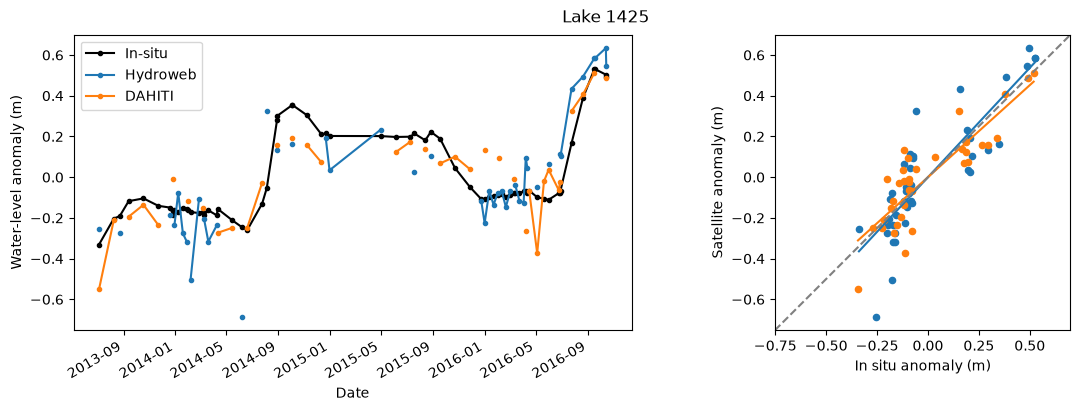

In [30]:
def plot_fit(ax, data, color):
    """Plot a two-column table and its linear fit."""
    x, y = data.iloc[:, 0], data.iloc[:, 1]
    ax.scatter(x, y, color=color, s=20)
    if x.nunique() > 1:
        limits = [x.min(), x.max()]
        ax.plot(limits, np.polyval(np.polyfit(x, y, 1), limits), color=color)

# 1. Prepare data.
lake_id = 1425
lake = matched_data_gdf.loc[matched_data_gdf['lake_id'] == lake_id]
if lake.empty:
    raise ValueError(f'No matched observations for lake {lake_id}.')
water_levels = lake.set_index('date')[[f'water_level_{s}' for s in ['insitu', 'hydroweb', 'dahiti']]].copy()
water_levels.columns = ['In-situ', 'Hydroweb', 'DAHITI']
water_levels.index = pd.to_datetime(water_levels.index)
water_levels = water_levels.sort_index()
insitu_hydroweb = water_levels[['In-situ', 'Hydroweb']].dropna()
insitu_hydroweb -= insitu_hydroweb.mean()  ## 
insitu_dahiti = water_levels[['In-situ', 'DAHITI']].dropna()
insitu_dahiti -= insitu_dahiti.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')

# 2. Left plot: center each source on its available dates.
water_levels = water_levels - water_levels.mean()
water_levels.plot(ax=ax1, marker='o', markersize=3, 
                    color=['black', 'tab:blue', 'tab:orange'])

ax1.set(xlabel='Date', ylabel='Water-level anomaly (m)')

# 3. Right plot: use shared-date anomalies; no legend.
plot_fit(ax2, insitu_hydroweb, 'tab:blue')
plot_fit(ax2, insitu_dahiti, 'tab:orange')
# Keep the right panel square with matching axis ranges.
bounds = ax2.get_xlim() + ax2.get_ylim()
limits = (min(bounds), max(bounds))
ax2.axline((0, 0), slope=1, linestyle='--', color='gray')
ax2.set(xlim=limits, ylim=limits, aspect='equal',
        xlabel='In situ anomaly (m)', ylabel='Satellite anomaly (m)')
fig.suptitle(f'Lake {lake_id}')


In [ ]:
scores = []
for lake_id, lake in matched_data.groupby('lake_id'):
    for source, column in [('hydroweb', 'water_level_hydroweb'), ('dahiti', 'water_level_dahiti')]:
        paired = lake[['water_level_insitu', column]].dropna()
        if len(paired) < 5:
            continue
        centered = paired - paired.mean()
        scores.append({
            'lake_id': lake_id, 'source': source, 'n': len(paired),
            'r': paired['water_level_insitu'].corr(paired[column]),
            'RMSE_zm': np.sqrt(((centered['water_level_insitu'] - centered[column]) ** 2).mean()),
        })
metrics = pd.DataFrame(scores, columns=['lake_id', 'source', 'n', 'r', 'RMSE_zm'])
metrics



,lake_id,source,n,r,RMSE_zm
0,149,hydroweb,78,0.634295,0.232799
1,149,dahiti,32,0.751839,0.215752
2,1399,hydroweb,27,0.185693,0.552870
3,1399,dahiti,31,-0.228600,0.463382
4,1401,hydroweb,8,0.381317,0.136302
5,1401,dahiti,12,0.810300,0.102436
6,1425,hydroweb,44,0.857766,0.148238
7,1425,dahiti,36,0.862512,0.117745
8,1449,hydroweb,260,0.917364,0.139997
9,1449,dahiti,229,0.733244,0.210664
